<a href="https://colab.research.google.com/github/MarnieGrenat/ukiyoe2photo_GANS/blob/main/GANS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GANS - Ukiyo-e to Photo
## Author: Gabriela Dellamora Paim

# Importações

In [1]:
import random
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torchvision.transforms as T

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)



In [2]:
# ==============================================================================
# SCRIPT DE DOWNLOAD E EXTRAÇÃO DO DATASET UKIYO2PHOTO
# ==============================================================================

import os
import zipfile
import urllib.request

# Definindo a URL oficial e o nome do arquivo
zip_path = "ukiyoe2photo.zip"
dataset_url = "https://efrosgans.eecs.berkeley.edu/cyclegan/datasets/" + zip_path
extract_path = "./dataset"

print("⏳ Iniciando o download do dataset (isso pode levar alguns minutos)...")

# Faz o download do arquivo zip direto para o Colab
urllib.request.urlretrieve(dataset_url, zip_path)
print("✅ Download concluído com sucesso!")

print("⏳ Extraindo os arquivos...")
# Descompacta o arquivo zip na pasta destino
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)
print("✅ Extração concluída!")

# Remove o arquivo .zip para economizar espaço em disco no Colab
os.remove(zip_path)
print("🧹 Arquivo ZIP temporário removido.")

# Exibe a estrutura de pastas gerada para confirmação
print("\n📁 Estrutura de pastas pronta para o treino:")
base_dir = os.path.join(extract_path, "ukiyoe2photo")
for folder in sorted(os.listdir(base_dir)):
    folder_path = os.path.join(base_dir, folder)
    if os.path.isdir(folder_path):
        print(f"   └── {folder}/ ({len(os.listdir(folder_path))} imagens)")

⏳ Iniciando o download do dataset (isso pode levar alguns minutos)...
✅ Download concluído com sucesso!
⏳ Extraindo os arquivos...
✅ Extração concluída!
🧹 Arquivo ZIP temporário removido.

📁 Estrutura de pastas pronta para o treino:
   └── testA/ (263 imagens)
   └── testB/ (751 imagens)
   └── trainA/ (562 imagens)
   └── trainB/ (6287 imagens)


In [8]:
TRAIN_PHOTO_PATH = Path("./dataset/ukiyoe2photo/trainA")
TRAIN_ART_PATH   = Path("./dataset/ukiyoe2photo/trainB")
TEST_PHOTO_PATH  = Path("./dataset/ukiyoe2photo/testA")
TEST_ART_PATH    = Path("./dataset/ukiyoe2photo/testB")


In [9]:
DOMAINS = {
    "Train / Photos (A)":  TRAIN_PHOTO_PATH,
    "Train / Ukiyo-e (B)": TRAIN_ART_PATH,
    "Test / Photos (A)":   TEST_PHOTO_PATH,
    "Test / Ukiyo-e (B)":  TEST_ART_PATH,
}

VALID_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

# Subsample size for the color analysis (full pass is slow on 6k+ photos)
COLOR_SAMPLE_SIZE = 500


# EDA

## Dataset integrity check

In [10]:
def list_images(folder: Path) -> list[Path]:
    """Return all image files in a folder, filtered by extension."""
    return sorted(
        p for p in folder.iterdir()
        if p.suffix.lower() in VALID_EXTENSIONS
    )


def check_integrity(folder: Path) -> dict:
    """Count images, detect corrupted files and collect format statistics."""
    paths = list_images(folder)
    corrupted = []
    formats = Counter()

    for path in paths:
        try:
            with Image.open(path) as img:
                img.verify()  # cheap corruption check (does not decode pixels)
                formats[img.format] += 1
        except Exception:
            corrupted.append(path)

    return {
        "total_images": len(paths),
        "corrupted": corrupted,
        "formats": dict(formats),
    }

In [11]:
print("=" * 60)
print("1. DATASET INTEGRITY")
print("=" * 60)
for name, folder in DOMAINS.items():
    if not folder.exists():
        print(f"{name}: FOLDER NOT FOUND -> {folder}")
        continue
    report = check_integrity(folder)
    print(f"\n{name}")
    print(f"  Images:    {report['total_images']}")
    print(f"  Formats:   {report['formats']}")
    print(f"  Corrupted: {len(report['corrupted'])}")
    for path in report["corrupted"]:
        print(f"    - {path}")

# Domain balance: relevant for training time and discriminator dynamics
n_photos = len(list_images(TRAIN_PHOTO_PATH))
n_art = len(list_images(TRAIN_ART_PATH))
print(f"\nDomain balance (train): {n_photos} photos vs {n_art} ukiyo-e")
print(f"Ratio A:B = {n_photos / max(n_art, 1):.2f} : 1")

1. DATASET INTEGRITY

Train / Photos (A)
  Images:    562
  Formats:   {'JPEG': 562}
  Corrupted: 0

Train / Ukiyo-e (B)
  Images:    6287
  Formats:   {'JPEG': 6287}
  Corrupted: 0

Test / Photos (A)
  Images:    263
  Formats:   {'JPEG': 263}
  Corrupted: 0

Test / Ukiyo-e (B)
  Images:    751
  Formats:   {'JPEG': 751}
  Corrupted: 0

Domain balance (train): 562 photos vs 6287 ukiyo-e
Ratio A:B = 0.09 : 1


## Resolution and aspect ratio statistics

In [12]:
def collect_image_metadata(folder: Path) -> pd.DataFrame:
    """Collect width, height and aspect ratio for every image in a folder."""
    records = []
    for path in list_images(folder):
        with Image.open(path) as img:
            width, height = img.size
        records.append({
            "file": path.name,
            "width": width,
            "height": height,
            "aspect_ratio": width / height,
            "orientation": (
                "landscape" if width > height
                else "portrait" if height > width
                else "square"
            ),
        })
    return pd.DataFrame(records)

2. RESOLUTION AND ASPECT RATIO

Train / Photos (A)
  Width  - min: 256, max: 256, median: 256
  Height - min: 256, max: 256, median: 256
  Orientation: {'square': 562}

Train / Ukiyo-e (B)
  Width  - min: 256, max: 256, median: 256
  Height - min: 256, max: 256, median: 256
  Orientation: {'square': 6287}

Test / Photos (A)
  Width  - min: 256, max: 256, median: 256
  Height - min: 256, max: 256, median: 256
  Orientation: {'square': 263}

Test / Ukiyo-e (B)
  Width  - min: 256, max: 256, median: 256
  Height - min: 256, max: 256, median: 256
  Orientation: {'square': 751}


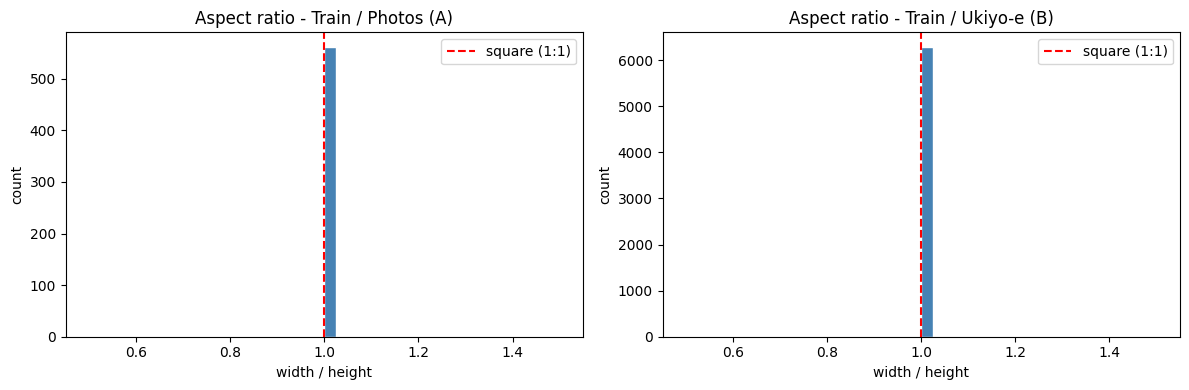

In [13]:
metadata = {
    name: collect_image_metadata(folder)
    for name, folder in DOMAINS.items()
    if folder.exists()
}

print("=" * 60)
print("2. RESOLUTION AND ASPECT RATIO")
print("=" * 60)
for name, df in metadata.items():
    print(f"\n{name}")
    print(f"  Width  - min: {df.width.min()}, max: {df.width.max()}, "
          f"median: {df.width.median():.0f}")
    print(f"  Height - min: {df.height.min()}, max: {df.height.max()}, "
          f"median: {df.height.median():.0f}")
    print(f"  Orientation: {df.orientation.value_counts().to_dict()}")

# %%
# Aspect ratio distributions: photos tend to be landscape,
# ukiyo-e prints are traditionally vertical (oban format, ~2:3).
train_domains = ["Train / Photos (A)", "Train / Ukiyo-e (B)"]

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, name in zip(axes, train_domains):
    df = metadata[name]
    ax.hist(df.aspect_ratio, bins=40, color="steelblue", edgecolor="white")
    ax.axvline(1.0, color="red", linestyle="--", label="square (1:1)")
    ax.set_title(f"Aspect ratio - {name}")
    ax.set_xlabel("width / height")
    ax.set_ylabel("count")
    ax.legend()
plt.tight_layout()
plt.savefig("eda_aspect_ratios.png", dpi=120)
plt.show()

## Color palette analysis
Ukiyo-e has a characteristic palette (Prussian blue, earthy tones, flat  color regions). Comparing RGB/HSV statistics between domains gives quantitative evidence of what the GAN must learn to transfer.


In [15]:
def sample_paths(folder: Path, k: int) -> list[Path]:
    """Random subsample of image paths (or all of them, if fewer than k)."""
    paths = list_images(folder)
    return random.sample(paths, k) if len(paths) > k else paths


def compute_color_stats(folder: Path, k: int = COLOR_SAMPLE_SIZE) -> dict:
    """Compute mean RGB histograms and HSV statistics over a subsample.

    Images are resized to 128x128 before analysis: global color statistics
    are resolution-independent, and this keeps the pass fast.
    """
    rgb_hist = np.zeros((3, 256), dtype=np.float64)
    hsv_means = []

    for path in sample_paths(folder, k):
        with Image.open(path) as img:
            rgb = np.asarray(img.convert("RGB").resize((128, 128)))
            hsv = np.asarray(img.convert("RGB").resize((128, 128)).convert("HSV"))

        for channel in range(3):
            hist, _ = np.histogram(rgb[..., channel], bins=256, range=(0, 256))
            rgb_hist[channel] += hist

        hsv_means.append(hsv.reshape(-1, 3).mean(axis=0))

    rgb_hist /= rgb_hist.sum(axis=1, keepdims=True)  # normalize to densities
    hsv_means = np.array(hsv_means)

    return {
        "rgb_hist": rgb_hist,
        "mean_hue": hsv_means[:, 0].mean(),
        "mean_saturation": hsv_means[:, 1].mean(),
        "mean_value": hsv_means[:, 2].mean(),
    }

3. COLOR STATISTICS (HSV means, 0-255 scale)

Train / Photos (A)
  Hue:        55.6
  Saturation: 68.4
  Brightness: 172.0

Train / Ukiyo-e (B)
  Hue:        92.5
  Saturation: 94.8
  Brightness: 123.6


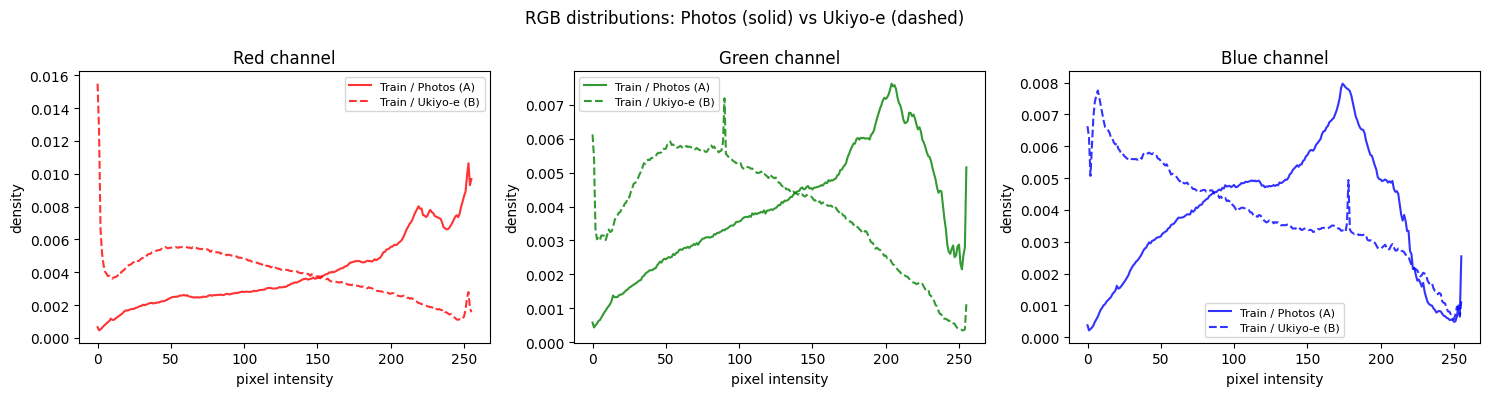

In [16]:
color_stats = {
    name: compute_color_stats(DOMAINS[name])
    for name in train_domains
}

print("=" * 60)
print("3. COLOR STATISTICS (HSV means, 0-255 scale)")
print("=" * 60)
for name, stats in color_stats.items():
    print(f"\n{name}")
    print(f"  Hue:        {stats['mean_hue']:.1f}")
    print(f"  Saturation: {stats['mean_saturation']:.1f}")
    print(f"  Brightness: {stats['mean_value']:.1f}")

# %%
# RGB histogram comparison between domains
channel_names = ["Red", "Green", "Blue"]
channel_colors = ["red", "green", "blue"]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ch, (ax, ch_name, ch_color) in enumerate(
    zip(axes, channel_names, channel_colors)
):
    for name, linestyle in zip(train_domains, ["-", "--"]):
        ax.plot(
            color_stats[name]["rgb_hist"][ch],
            color=ch_color,
            linestyle=linestyle,
            label=name,
            alpha=0.8,
        )
    ax.set_title(f"{ch_name} channel")
    ax.set_xlabel("pixel intensity")
    ax.set_ylabel("density")
    ax.legend(fontsize=8)
plt.suptitle("RGB distributions: Photos (solid) vs Ukiyo-e (dashed)")
plt.tight_layout()
plt.savefig("eda_color_histograms.png", dpi=120)
plt.show()

## Sample grids for visual inspection
Manual inspection matters: look for scanning borders / frames on the **prints**, semantic mismatch (portraits vs landscapes) and duplicates.

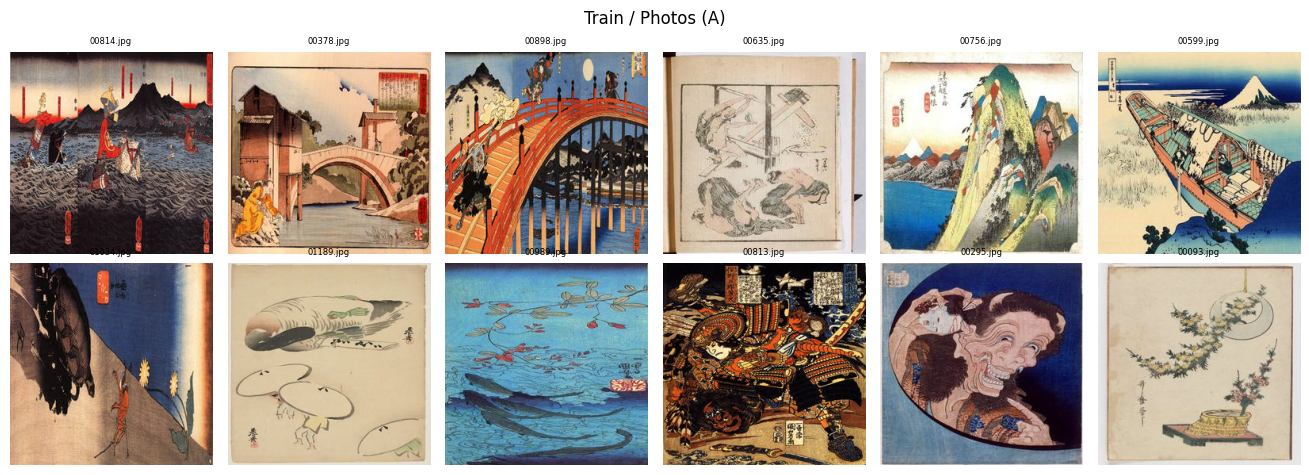

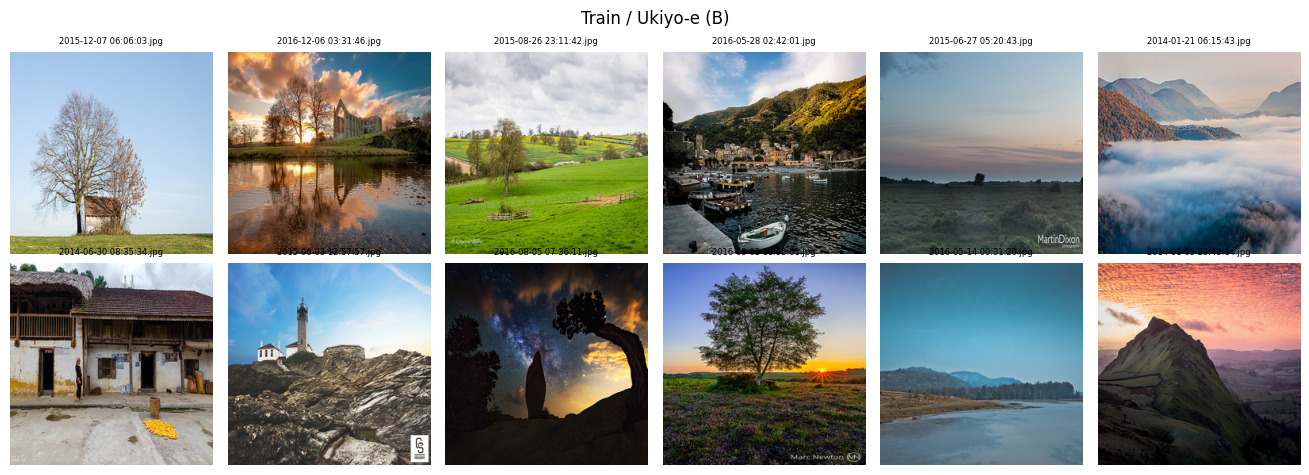

In [18]:
def show_sample_grid(folder: Path, title: str, n_rows: int = 2,
                     n_cols: int = 6) -> None:
    """Display a grid of random samples from a domain."""
    paths = sample_paths(folder, n_rows * n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(2.2 * n_cols, 2.4 * n_rows))
    for ax, path in zip(axes.flat, paths):
        with Image.open(path) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(path.name, fontsize=6)
        ax.axis("off")
    plt.suptitle(title)
    plt.tight_layout()
    plt.savefig(f"eda_samples_{title.split('/')[0].strip().lower()}_"
                f"{'A' if '(A)' in title else 'B'}.png", dpi=120)
    plt.show()


show_sample_grid(TRAIN_PHOTO_PATH, "Train / Photos (A)")
show_sample_grid(TRAIN_ART_PATH, "Train / Ukiyo-e (B)")

## Preprocessing Pipeline

In [19]:
# Standard CycleGAN augmentation:
#   resize to 286 -> random crop 256 -> random horizontal flip -> [-1, 1]
train_transform = T.Compose([
    T.Resize(286, interpolation=T.InterpolationMode.BICUBIC),
    T.RandomCrop(256),
    T.RandomHorizontalFlip(p=0.5),
    T.ToTensor(),                                   # [0, 1]
    T.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5)),  # [-1, 1]
])


def denormalize(tensor: torch.Tensor) -> np.ndarray:
    """Map a [-1, 1] CHW tensor back to a displayable [0, 1] HWC array."""
    return (tensor.permute(1, 2, 0).numpy() * 0.5 + 0.5).clip(0, 1)


def preview_transform(folder: Path, title: str, n_samples: int = 4) -> None:
    """Show original images next to their augmented training versions."""
    paths = sample_paths(folder, n_samples)

    fig, axes = plt.subplots(2, n_samples, figsize=(3 * n_samples, 6))
    for col, path in enumerate(paths):
        with Image.open(path) as img:
            original = img.convert("RGB")
        transformed = train_transform(original)

        axes[0, col].imshow(original)
        axes[0, col].set_title("original", fontsize=8)
        axes[1, col].imshow(denormalize(transformed))
        axes[1, col].set_title("after transform (256x256)", fontsize=8)
        for row in range(2):
            axes[row, col].axis("off")
    plt.suptitle(f"Preprocessing preview - {title}")
    plt.tight_layout()
    plt.savefig(f"eda_preprocessing_{'A' if '(A)' in title else 'B'}.png",
                dpi=120)
    plt.show()

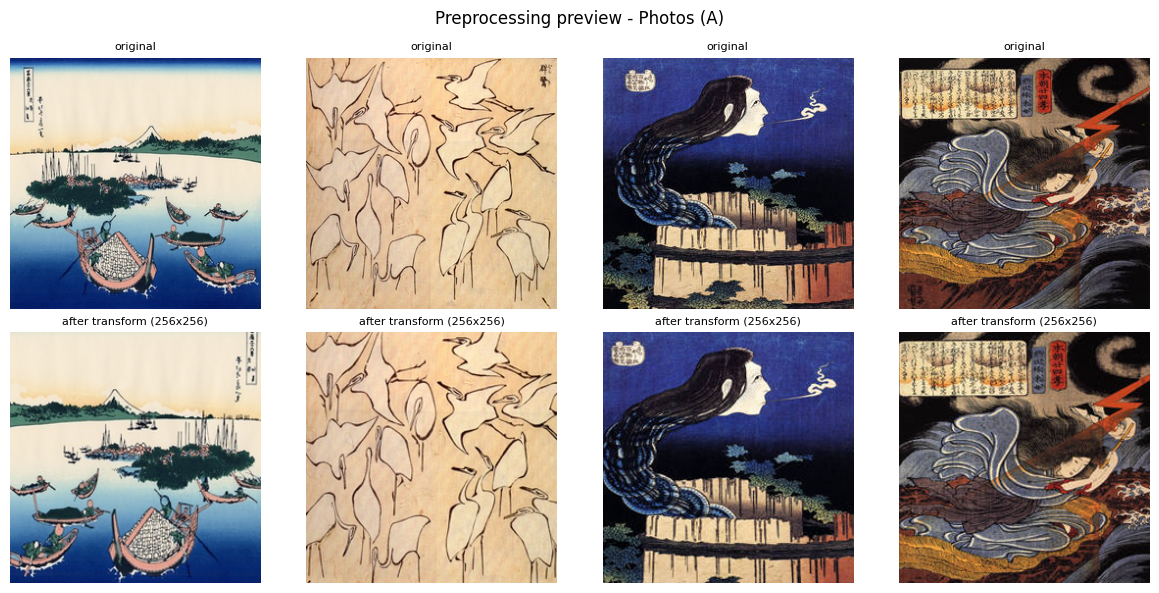

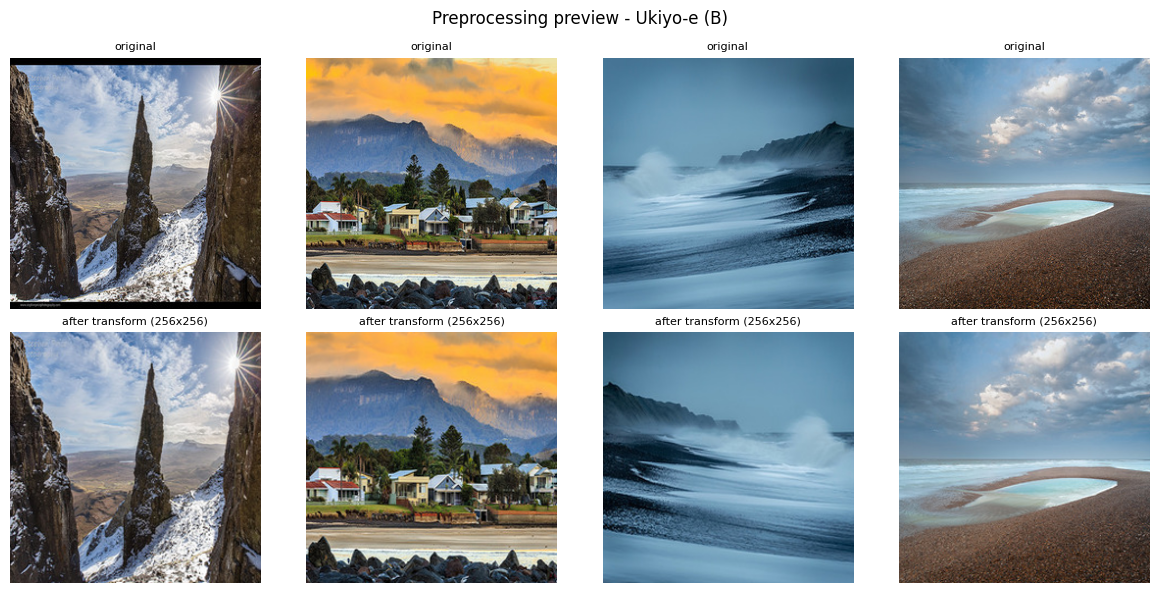

In [20]:
preview_transform(TRAIN_PHOTO_PATH, "Photos (A)")
preview_transform(TRAIN_ART_PATH, "Ukiyo-e (B)")

## Summary

In [22]:
print("=" * 60)
print("EDA SUMMARY")
print("=" * 60)
print(f"Train A (photos):  {n_photos} images")
print(f"Train B (ukiyo-e): {n_art} images")
print(f"Test A:            {len(list_images(TEST_PHOTO_PATH))} images")
print(f"Test B:            {len(list_images(TEST_ART_PATH))} images")
print()
print("Artifacts saved:")
print("  - eda_aspect_ratios.png")
print("  - eda_color_histograms.png")
print("  - eda_samples_*.png")
print("  - eda_preprocessing_*.png")
print()
print("Checklist before moving to Phase 2:")
print("  [X] No corrupted images (or removed)")
print("  [ ] Scanning borders/frames on prints inspected")
print("  [ ] Semantic coherence between domains verified")
print("  [ ] Domain balance decision made (subsample A or not)")


EDA SUMMARY
Train A (photos):  562 images
Train B (ukiyo-e): 6287 images
Test A:            263 images
Test B:            751 images

Artifacts saved:
  - eda_aspect_ratios.png
  - eda_color_histograms.png
  - eda_samples_*.png
  - eda_preprocessing_*.png

Checklist before moving to Phase 2:
  [X] No corrupted images (or removed)
  [ ] Scanning borders/frames on prints inspected
  [ ] Semantic coherence between domains verified
  [ ] Domain balance decision made (subsample A or not)
